In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.pipeline import Pipeline

print("All libraries imported successfully!")

All libraries imported successfully!


In [9]:
file_path = '/kaggle/input/datasets/samuelsemaya/e-commerce-customer-churn/data_ecommerce_customer_churn.csv'

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset loaded successfully!
Dataset Shape: (3941, 11)

First 5 Rows:


,Tenure,WarehouseToHome,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,Churn
0,15.0,29.0,4,Laptop & Accessory,3,Single,2,0,7.0,143.32,0
1,7.0,25.0,4,Mobile,1,Married,2,0,7.0,129.29,0
2,27.0,13.0,3,Laptop & Accessory,1,Married,5,0,7.0,168.54,0
3,20.0,25.0,4,Fashion,3,Divorced,7,0,NaN,230.27,0
4,30.0,15.0,4,Others,4,Single,8,0,8.0,322.17,0



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3941 entries, 0 to 3940
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Tenure                    3747 non-null   float64
 1   WarehouseToHome           3772 non-null   float64
 2   NumberOfDeviceRegistered  3941 non-null   int64  
 3   PreferedOrderCat          3941 non-null   object 
 4   SatisfactionScore         3941 non-null   int64  
 5   MaritalStatus             3941 non-null   object 
 6   NumberOfAddress           3941 non-null   int64  
 7   Complain                  3941 non-null   int64  
 8   DaySinceLastOrder         3728 non-null   float64
 9   CashbackAmount            3941 non-null   float64
 10  Churn                     3941 non-null   int64  
dtypes: float64(4), int64(5), object(2)
memory usage: 338.8+ KB

Missing Values:
Tenure                      194
WarehouseToHome             169
NumberOfDev

In [10]:
target_col = 'Churn'

if target_col not in df.columns:
    raise ValueError("Churn column was not found in the dataset!")

X_raw = df.drop(columns=[target_col])
y_raw = df[target_col]

# Convert target into binary classification
if set(pd.Series(y_raw).dropna().unique()).issubset({0, 1, 0.0, 1.0}):
    y = y_raw.astype(int).values

else:
    target_mapping = {
        'yes': 1,
        'no': 0,
        'true': 1,
        'false': 0,
        '1': 1,
        '0': 0,
        'churn': 1,
        'not churn': 0,
        'left': 1,
        'stayed': 0,
        '1.0': 1,
        '0.0': 0
    }

    y = y_raw.astype(str).str.strip().str.lower().map(target_mapping)

    if y.isnull().any():
        raise ValueError(
            "Unknown target labels. Check Churn values: "
            + str(y_raw.unique())
        )

    y = y.astype(int).values

print("Target encoding completed!")

print("0 = Customer will stay")
print("1 = Customer will leave")

print("\nClass Distribution:")
print(pd.Series(y).value_counts().sort_index())

Target encoding completed!
0 = Customer will stay
1 = Customer will leave

Class Distribution:
0    3267
1     674
Name: count, dtype: int64


In [11]:
X_train_raw, X_test_raw, Y_train, Y_test = train_test_split(
    X_raw,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train_raw.shape[0])
print("Testing samples:", X_test_raw.shape[0])

print("\nTraining Class Distribution:")
print(np.bincount(Y_train))

print("\nTesting Class Distribution:")
print(np.bincount(Y_test))

Training samples: 3152
Testing samples: 789

Training Class Distribution:
[2613  539]

Testing Class Distribution:
[654 135]


In [12]:
# Identify numerical and categorical columns
numeric_features = X_train_raw.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train_raw.select_dtypes(
    exclude=np.number
).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    sparse_threshold=0.0
)

# Fit only on training data
X_train_scaled = preprocessor.fit_transform(X_train_raw)
X_test_scaled = preprocessor.transform(X_test_raw)

# Convert to NumPy arrays
X_train_scaled = np.asarray(X_train_scaled, dtype=float)
X_test_scaled = np.asarray(X_test_scaled, dtype=float)

# Add bias column
X_train_bias = np.c_[
    np.ones(X_train_scaled.shape[0]),
    X_train_scaled
]

X_test_bias = np.c_[
    np.ones(X_test_scaled.shape[0]),
    X_test_scaled
]

print("Preprocessing completed successfully!")

print("Training Shape:", X_train_bias.shape)
print("Testing Shape:", X_test_bias.shape)
print("Number of Features:", X_train_scaled.shape[1])

Preprocessing completed successfully!
Training Shape: (3152, 18)
Testing Shape: (789, 18)
Number of Features: 17


In [16]:
def sigmoid(z):
    z = np.clip(z, -250, 250)
    return 1 / (1 + np.exp(-z))

In [18]:
def compute_bce_loss(Y_true, Y_prob):

    epsilon = 1e-15

    Y_prob = np.clip(
        Y_prob,
        epsilon,
        1 - epsilon
    )

    m = len(Y_true)

    loss = -(1 / m) * np.sum(
        Y_true * np.log(Y_prob)
        +
        (1 - Y_true) * np.log(1 - Y_prob)
    )

    return loss

In [19]:
def evaluate_classification_metrics(
    Y_true,
    Y_pred_prob,
    threshold=0.5
):

    Y_pred = (Y_pred_prob >= threshold).astype(int)

    tp = np.sum((Y_true == 1) & (Y_pred == 1))
    tn = np.sum((Y_true == 0) & (Y_pred == 0))
    fp = np.sum((Y_true == 0) & (Y_pred == 1))
    fn = np.sum((Y_true == 1) & (Y_pred == 0))

    accuracy = (tp + tn) / len(Y_true)

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0

    recall = tp / (tp + fn) if (tp + fn) > 0 else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0 else 0
    )

    return {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'TP': tp,
        'TN': tn,
        'FP': fp,
        'FN': fn
    }

print("Logistic Regression functions are ready!")

Logistic Regression functions are ready!


In [20]:
def logistic_gradient_descent(
    X,
    Y,
    learning_rate=0.05,
    epochs=1000
):

    m, n = X.shape

    # Initialize weights
    weights = np.zeros(n)

    loss_history = []

    for epoch in range(epochs):

        # Forward propagation
        z = np.dot(X, weights)

        predictions = sigmoid(z)

        # Calculate error
        error = predictions - Y

        # Calculate gradient
        gradient = (1 / m) * np.dot(X.T, error)

        # Update weights using standard GD
        weights -= learning_rate * gradient

        # Calculate loss after weight update
        updated_predictions = sigmoid(np.dot(X, weights))

        loss = compute_bce_loss(Y, updated_predictions)

        loss_history.append(loss)

    return weights, loss_history


print("Gradient Descent function defined successfully!")

Gradient Descent function defined successfully!


In [21]:
learning_rate = 0.05
epochs = 1000

optimal_weights_gd, losses_gd = logistic_gradient_descent(
    X_train_bias,
    Y_train,
    learning_rate=learning_rate,
    epochs=epochs
)

print("Gradient Descent Training Completed!")
print("Learning Rate:", learning_rate)
print("Epochs:", epochs)
print("Initial Training Loss:", round(losses_gd[0], 4))
print("Final Training Loss:", round(losses_gd[-1], 4))

Gradient Descent Training Completed!
Learning Rate: 0.05
Epochs: 1000
Initial Training Loss: 0.682
Final Training Loss: 0.2965


In [23]:
# Predict probabilities on test data
test_probs_gd = sigmoid(
    np.dot(X_test_bias, optimal_weights_gd)
)

# Calculate test loss
test_loss_gd = compute_bce_loss(
    Y_test,
    test_probs_gd
)

# Calculate evaluation metrics
metrics_gd = evaluate_classification_metrics(
    Y_test,
    test_probs_gd
)

# Display results
print("=" * 65)
print("LOGISTIC REGRESSION - GRADIENT DESCENT")
print("E-COMMERCE CUSTOMER CHURN")
print("=" * 65)

print(f"Test Loss       : {test_loss_gd:.4f}")
print(f"Accuracy        : {metrics_gd['Accuracy'] * 100:.2f}%")
print(f"Precision       : {metrics_gd['Precision'] * 100:.2f}%")
print(f"Recall          : {metrics_gd['Recall'] * 100:.2f}%")
print(f"F1-Score        : {metrics_gd['F1-Score'] * 100:.2f}%")

print("=" * 65)

print("\nConfusion Matrix Values:")
print("True Positive :", metrics_gd['TP'])
print("True Negative :", metrics_gd['TN'])
print("False Positive:", metrics_gd['FP'])
print("False Negative:", metrics_gd['FN'])

LOGISTIC REGRESSION - GRADIENT DESCENT
E-COMMERCE CUSTOMER CHURN
Test Loss       : 0.3043
Accuracy        : 86.82%
Precision       : 71.83%
Recall          : 37.78%
F1-Score        : 49.51%

Confusion Matrix Values:
True Positive : 51
True Negative : 634
False Positive: 20
False Negative: 84


In [25]:
Y_pred_gd = (test_probs_gd >= 0.5).astype(int)

print("Classification Report - GD")
print("=" * 60)

print(
    classification_report(
        Y_test,
        Y_pred_gd,
        labels=[0, 1],
        target_names=['Not Churn (0)', 'Churn (1)'],
        zero_division=0
    )
)

Classification Report - GD
               precision    recall  f1-score   support

Not Churn (0)       0.88      0.97      0.92       654
    Churn (1)       0.72      0.38      0.50       135

     accuracy                           0.87       789
    macro avg       0.80      0.67      0.71       789
 weighted avg       0.85      0.87      0.85       789



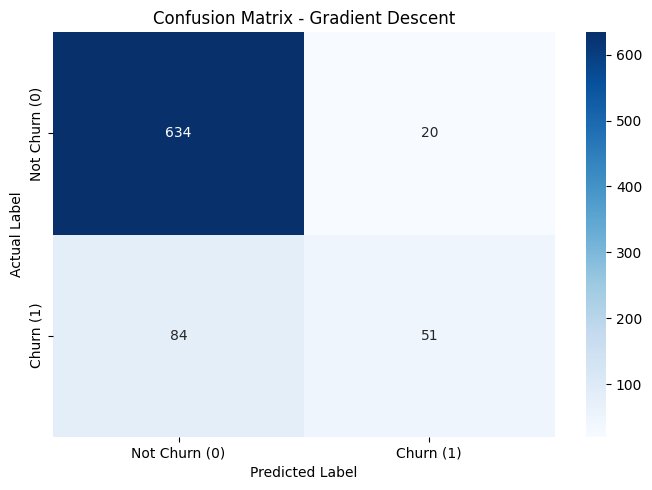

In [26]:
cm = confusion_matrix(
    Y_test,
    Y_pred_gd,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Churn (0)', 'Churn (1)'],
    yticklabels=['Not Churn (0)', 'Churn (1)']
)

plt.title('Confusion Matrix - Gradient Descent')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

plt.tight_layout()
plt.show()

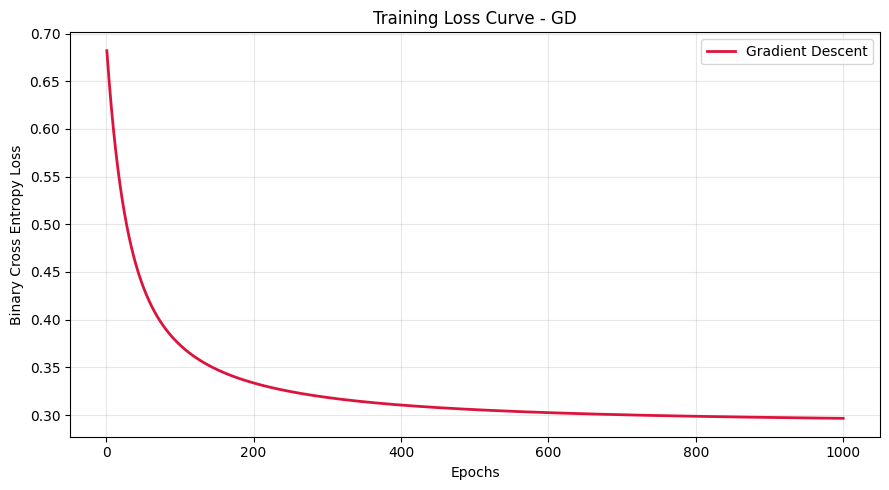

In [27]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, epochs + 1),
    losses_gd,
    color='crimson',
    linewidth=2,
    label='Gradient Descent'
)

plt.xlabel('Epochs')
plt.ylabel('Binary Cross Entropy Loss')
plt.title('Training Loss Curve - GD')

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

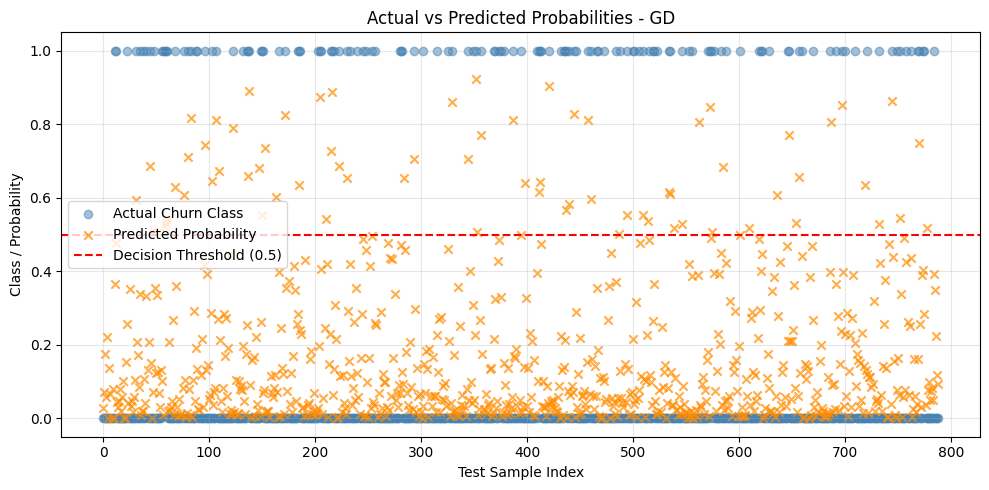

In [28]:
plt.figure(figsize=(10, 5))

plt.scatter(
    range(len(Y_test)),
    Y_test,
    color='steelblue',
    alpha=0.5,
    label='Actual Churn Class'
)

plt.scatter(
    range(len(test_probs_gd)),
    test_probs_gd,
    color='darkorange',
    marker='x',
    alpha=0.7,
    label='Predicted Probability'
)

plt.axhline(
    y=0.5,
    color='red',
    linestyle='--',
    label='Decision Threshold (0.5)'
)

plt.xlabel('Test Sample Index')
plt.ylabel('Class / Probability')
plt.title('Actual vs Predicted Probabilities - GD')

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

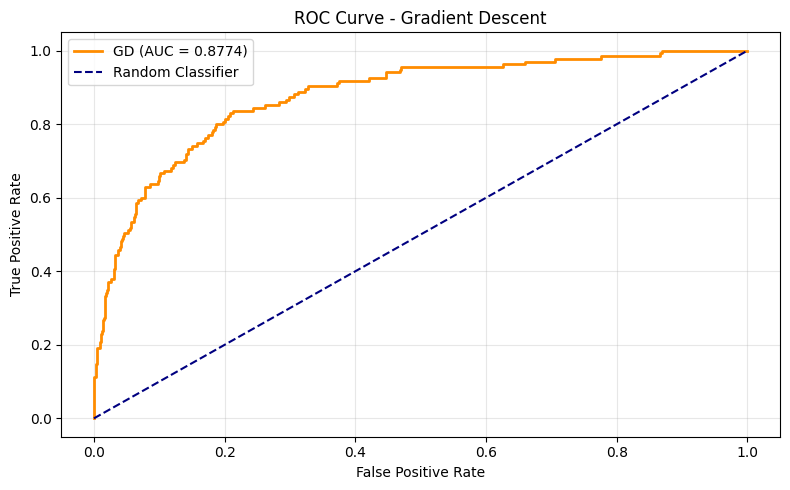

ROC-AUC Score: 0.8774


In [29]:
fpr, tpr, thresholds = roc_curve(
    Y_test,
    test_probs_gd
)

auc_score = roc_auc_score(
    Y_test,
    test_probs_gd
)

plt.figure(figsize=(8, 5))

plt.plot(
    fpr,
    tpr,
    color='darkorange',
    linewidth=2,
    label=f'GD (AUC = {auc_score:.4f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    color='navy',
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Gradient Descent')

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("ROC-AUC Score:", round(auc_score, 4))

In [30]:
gd_results = pd.DataFrame([{
    'Optimizer': 'GD',
    'Accuracy': metrics_gd['Accuracy'],
    'Precision': metrics_gd['Precision'],
    'Recall': metrics_gd['Recall'],
    'F1-Score': metrics_gd['F1-Score'],
    'Loss': test_loss_gd,
    'ROC-AUC': auc_score
}])

print("=" * 80)
print("FINAL RESULTS - GRADIENT DESCENT")
print("=" * 80)

display(
    gd_results.style.format({
        'Accuracy': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1-Score': '{:.4f}',
        'Loss': '{:.4f}',
        'ROC-AUC': '{:.4f}'
    })
)

FINAL RESULTS - GRADIENT DESCENT


,Optimizer,Accuracy,Precision,Recall,F1-Score,Loss,ROC-AUC
0,GD,0.8682,0.7183,0.3778,0.4951,0.3043,0.8774
